# Stage 4A — same-mask random-reinitialization controls

Exactly **18 new controls**: A (162–421), B (200–204), C (231–77) × original model seeds 0/1/2 × saved masks at rounds 6/12. No original ticket is retrained, no pruning mask is regenerated, and no held-out test evaluation is launched.

Each fresh Glorot-normal control uses seed `(model_seed + 1000003 + round*1009) % 2**32`, zero biases, the exact saved mask, fresh Adam 0.0012, the same full MNIST 55,000/5,000 split (seed 42), batch size 60 and corresponding ticket batch order. Train for 10,000 fixed updates; evaluate every 100; select accuracy at minimum validation loss. All outputs go to `reports/stage4_controls/`.

The original training/pruning source files are unchanged. An audit callback records actual example order, checks masked zeros and saves true minimum-loss control snapshots. Checkpoint recording does not feed back into training. Independent spawned processes use one CPU thread each; the standalone runner has the macOS/Windows main guard. Run from the repository root with the project Python kernel.

In [1]:
import os,sys,json,time,subprocess,tempfile
from pathlib import Path
os.environ.setdefault("MPLCONFIGDIR",str(Path(tempfile.gettempdir())/"lottery-stage4-mpl"))
import pandas as pd
from IPython.display import display,Image,Markdown
from tqdm.auto import tqdm
from filelock import FileLock,Timeout
from stage4_controls_runner import REPORT,initialize_study
REPORT.mkdir(parents=True,exist_ok=True)
if not (REPORT/"protocol.lock.json").exists():
    initialize_study()
display(json.loads((REPORT/"protocol.lock.json").read_text()))
display(Markdown((REPORT/"stage3_checkpoint_audit.md").read_text()))

{'architectures': {'A': [162, 421], 'B': [200, 204], 'C': [231, 77]},
 'model_seeds': [0, 1, 2],
 'rounds': [6, 12],
 'controls': 18,
 'iterations': 10000,
 'eval_interval': 100,
 'batch_size': 60,
 'learning_rate': 0.0012,
 'split_seed': 42,
 'optimizer': 'fresh Adam',
 'initialization': 'fresh Gaussian Glorot, zero biases',
 'control_seed_rule': '(seed+1000003+stage*1009)%2**32',
 'masks': 'exact saved Stage 3 positions; no regeneration',
 'test_evaluated': False,
 'core_sha256': {'experiment.py': '73b528d2421d6fbd1ab18ce85dd810002abbed87a4d443fa8a9017ccb40681b4',
  'train.py': 'ba0e9d92a320437a11eaf977f5b225e586e653e1483c96b094fe823b2a742329',
  'pruning.py': 'f182e00eab6cd8289fa1e9ab9a9dc64b6d0f393665af716f844d968073329781',
  'models.py': 'af362604ad3395aaed0976f6a2d131d99207b82ccc9d45ded08bd3f9417ca9ec',
  'data.py': '4b23113ec2ccff7417347e745076da46aa66a53e86c4e1527799fe3794166673',
  'checkpoints.py': '71688555e1cc0dfe4f8a15318e42a50ee38e239883ae338d22eb3369d318665e'},
 'runner

# Stage 3 minimum-loss checkpoint audit

Inspected all **117 ticket stages** and all saved tensor filenames/checkpoint schemas. The immutable Stage 3 engine saved original initialization, each masked start and the **final 10,000-update state**. It did not save a best-validation tensor snapshot or restore a best state before saving. Best-validation metrics and histories were saved, but metrics alone cannot reconstruct weights.

Minimum-loss states available without replay: **0/117**. None of the current Stage 3 minima was at update 10,000, so its final checkpoints cannot stand in for the selected checkpoints.

**Final test evaluation at the reported minimum-validation-loss states requires deterministic training replay.** Saved starts, masks, model/data seeds and exact histories allow a separately authorized replay to each selected iteration, with fresh Adam and the original batch order; no pruning should be regenerated. Validation metrics should then be checked before any test evaluation. No such replay is performed here.

**Final-weight test evaluation is possible without retraining**, using the saved 10,000-update states, but that is a different estimand from the reported validation-selected results and must be labeled separately. Do not silently substitute final states for selected ones.

Stage 4 controls save actual `best_validation.pt` snapshots during training as well as their initial/start/final states. Selected-state control evaluation will therefore be possible without control retraining, but a paired selected-state ticket comparison still needs the missing ticket snapshots. The test set remains unevaluated.


## Run or reuse only the 18 approved controls

If the controller is already active, observe its commits instead of launching duplicate workers. Completed controls are checksummed and skipped. An interrupted incomplete control restarts from its predetermined fresh initialization and the same saved mask; original tickets remain untouched. A complete notebook rerun performs analysis only.

In [2]:
execution_path=REPORT/"execution.json"
def state():
    return json.loads(execution_path.read_text()) if execution_path.exists() else {}
def active():
    try:
        with FileLock(str(REPORT/"runner.lock"),timeout=0):
            return False
    except Timeout:
        return True
with tqdm(total=18,desc="Verified control completions",unit="control") as bar:
    committed=len(list((REPORT/"runs").glob("*/complete.json")))
    bar.update(committed)
    if state().get("status")!="complete":
        if active():
            while active():
                now=len(list((REPORT/"runs").glob("*/complete.json")))
                bar.update(max(0,now-bar.n))
                if state().get("status")=="complete":
                    break
                time.sleep(5)
            if state().get("status")!="complete":
                raise RuntimeError("Runner stopped; rerun this cell to restart only incomplete controls.")
        else:
            with (REPORT/"notebook_runner.log").open("a") as log:
                subprocess.run([sys.executable,"stage4_controls_runner.py","--workers","3"],
                               stdout=log,stderr=subprocess.STDOUT,check=True)
    bar.update(max(0,18-bar.n))
execution=state()
assert execution["status"]=="complete" and len(execution["completed"])==18
print("All 18 controls complete. Original ticket trainings: 0. Test evaluations: 0.")
print("Parallel wall minutes:",execution["elapsed_seconds"]/60)

Verified control completions:   0%|          | 0/18 [00:00<?, ?control/s]

All 18 controls complete. Original ticket trainings: 0. Test evaluations: 0.
Parallel wall minutes: 6.442069170166663


## Paired metrics and sample variability

Every pair has identical architecture and active positions. Compute ticket-minus-control differences **within architecture/seed/round**, then mean and sample SD (ddof=1) across the three seeds. Gray segments connect corresponding observations. Positive accuracy difference favors the original ticket; negative favors random reinitialization. Bands/error bars are SD, not confidence intervals. Do not pool the 18 correlated pairs as independent replicates.

,architecture,seed,stage,remaining_parameters_ticket,best_validation_accuracy_ticket,best_validation_accuracy_control,ticket_minus_control_accuracy_pp,best_validation_loss_ticket,best_validation_loss_control,best_iteration_ticket,best_iteration_control
0,A,0,6,54008,0.9810,0.9796,0.14,0.065540,0.078102,2600,8100
1,A,0,12,15203,0.9794,0.9718,0.76,0.069222,0.087682,3300,9200
2,A,1,6,54008,0.9802,0.9782,0.20,0.066295,0.070513,2300,4800
3,A,1,12,15203,0.9794,0.9760,0.34,0.067542,0.088372,2700,9100
4,A,2,6,54008,0.9788,0.9794,-0.06,0.065683,0.079637,1900,8300
5,A,2,12,15203,0.9792,0.9722,0.70,0.071256,0.087641,2500,9900
6,B,0,6,53301,0.9820,0.9766,0.54,0.060922,0.081374,2500,7500
7,B,0,12,14575,0.9810,0.9708,1.02,0.067912,0.099902,2900,9800
8,B,1,6,53301,0.9798,0.9810,-0.12,0.064268,0.076252,1900,8500
9,B,1,12,14575,0.9814,0.9754,0.60,0.064145,0.091624,2700,9800


,architecture,stage,ticket_minus_control_accuracy_pp_mean,ticket_minus_control_accuracy_pp_std,ticket_minus_control_accuracy_pp_min,ticket_minus_control_accuracy_pp_max,ticket_minus_control_loss_mean,ticket_minus_control_loss_std,ticket_minus_control_loss_min,ticket_minus_control_loss_max,ticket_minus_control_iteration_mean,ticket_minus_control_iteration_std,ticket_minus_control_iteration_min,ticket_minus_control_iteration_max,seed_count,ticket_accuracy_higher_count,control_accuracy_higher_count,accuracy_tied_count,remaining_parameters
0,A,6,0.093333,0.136137,-0.06,0.20,-0.010245,0.005265,-0.013954,-0.004219,-4800.000000,2042.057786,-6400,-2500,3,2,1,0,54008
1,A,12,0.600000,0.227156,0.34,0.76,-0.018558,0.002224,-0.020829,-0.016385,-6566.666667,763.762616,-7400,-5900,3,3,0,0,15203
2,B,6,0.233333,0.332466,-0.12,0.54,-0.017678,0.004932,-0.020599,-0.011984,-5700.000000,818.535277,-6600,-5000,3,2,1,0,53301
3,B,12,0.766667,0.223010,0.60,1.02,-0.028511,0.003094,-0.031989,-0.026064,-6333.333333,1159.022577,-7100,-5000,3,3,0,0,14575
4,C,6,0.280000,0.131149,0.14,0.40,-0.015887,0.006212,-0.020515,-0.008827,-5766.666667,208.166600,-6000,-5600,3,3,0,0,52870
5,C,12,1.106667,0.133167,1.02,1.26,-0.034298,0.006574,-0.039881,-0.027052,-5300.000000,721.110255,-6100,-4700,3,3,0,0,14209


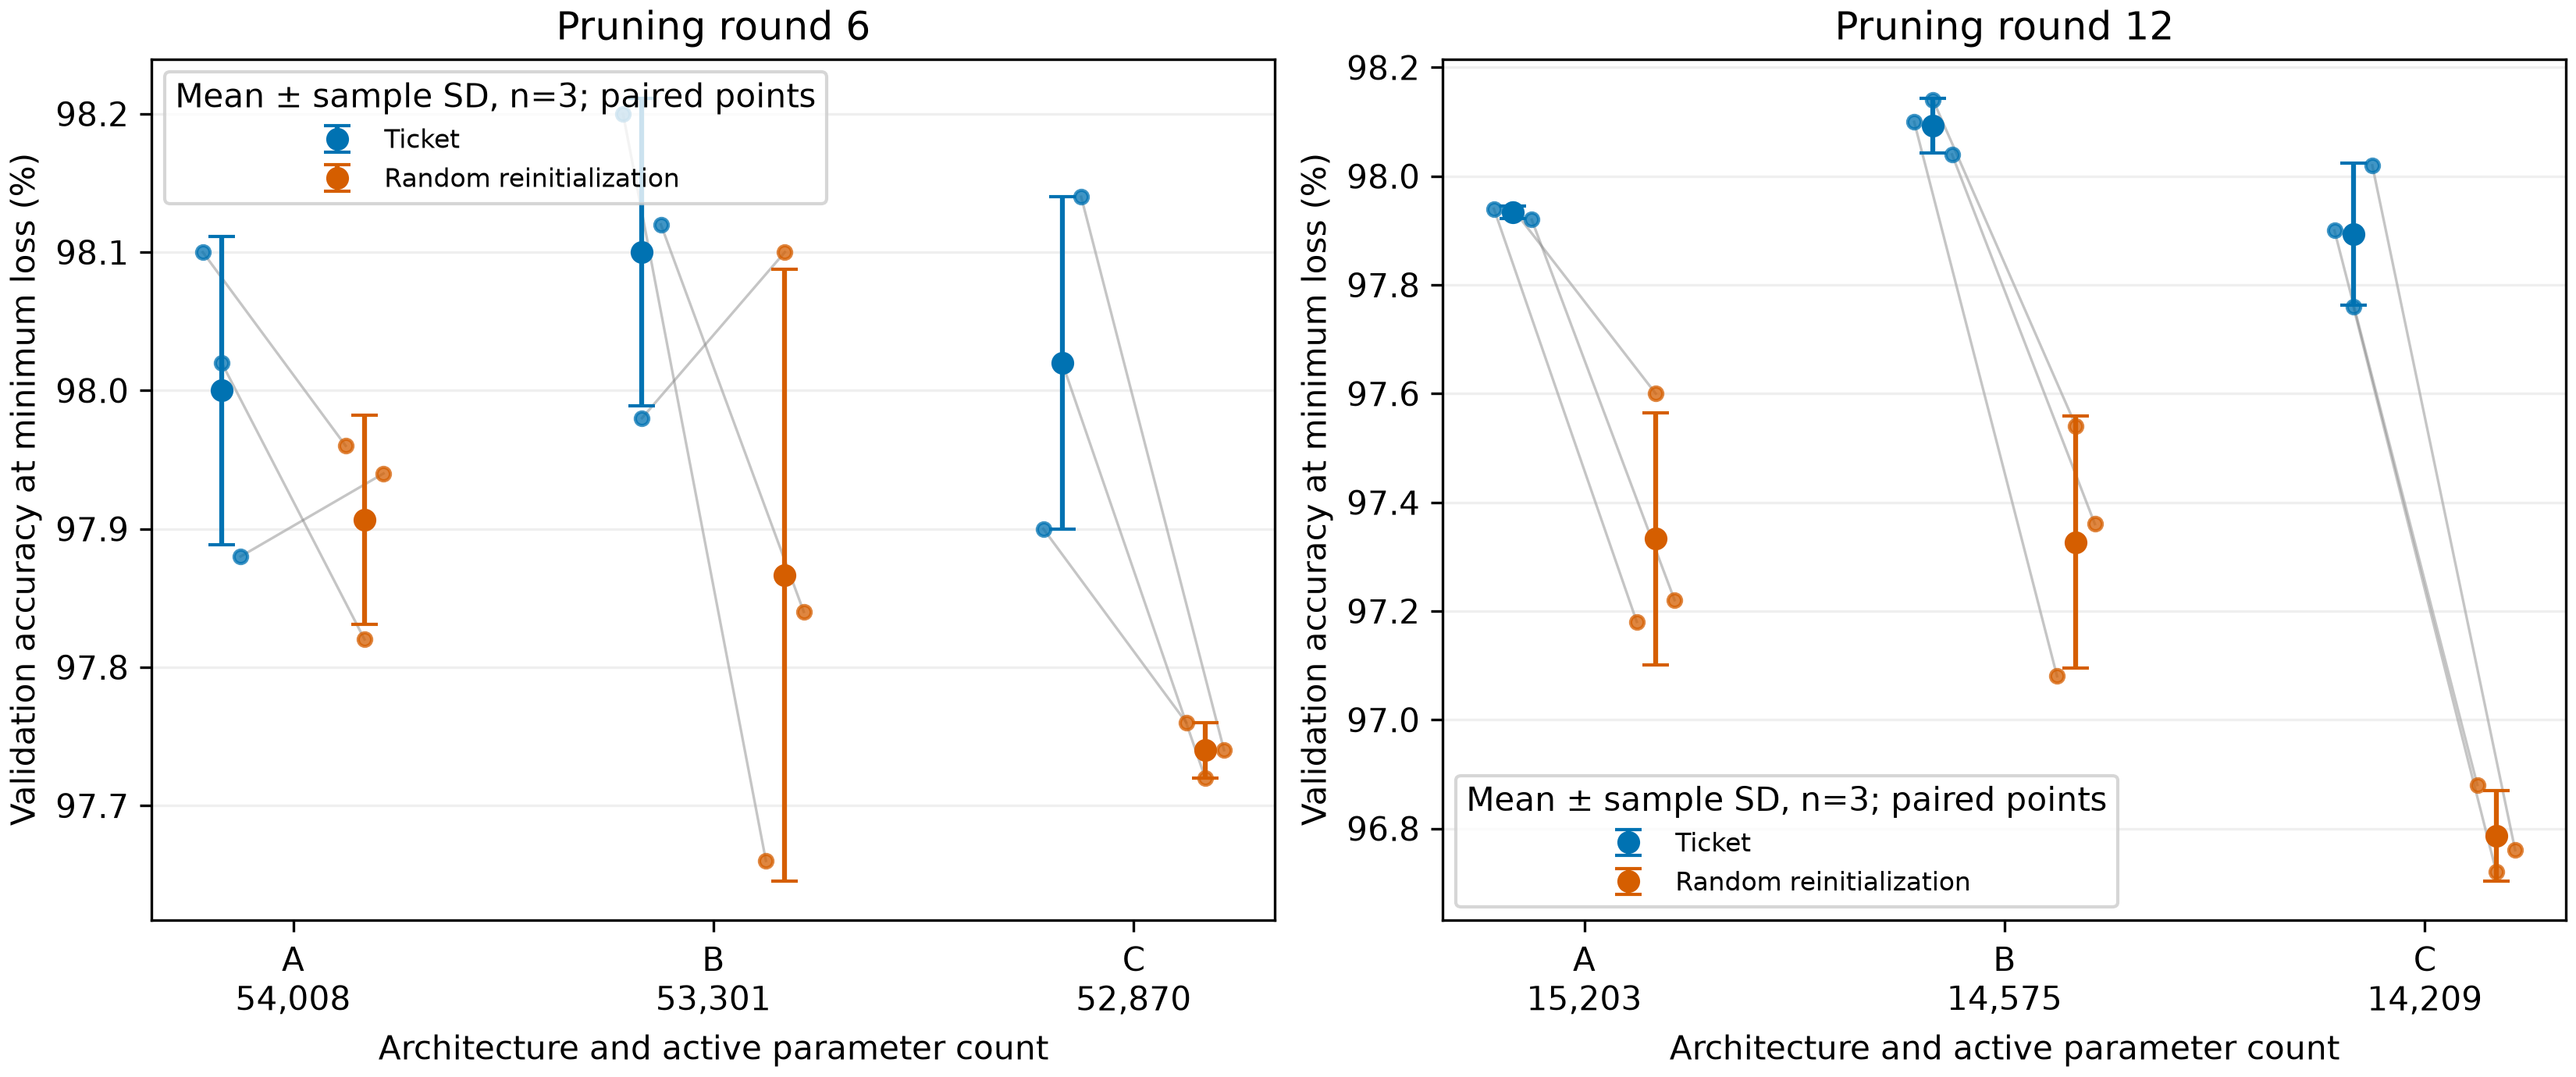

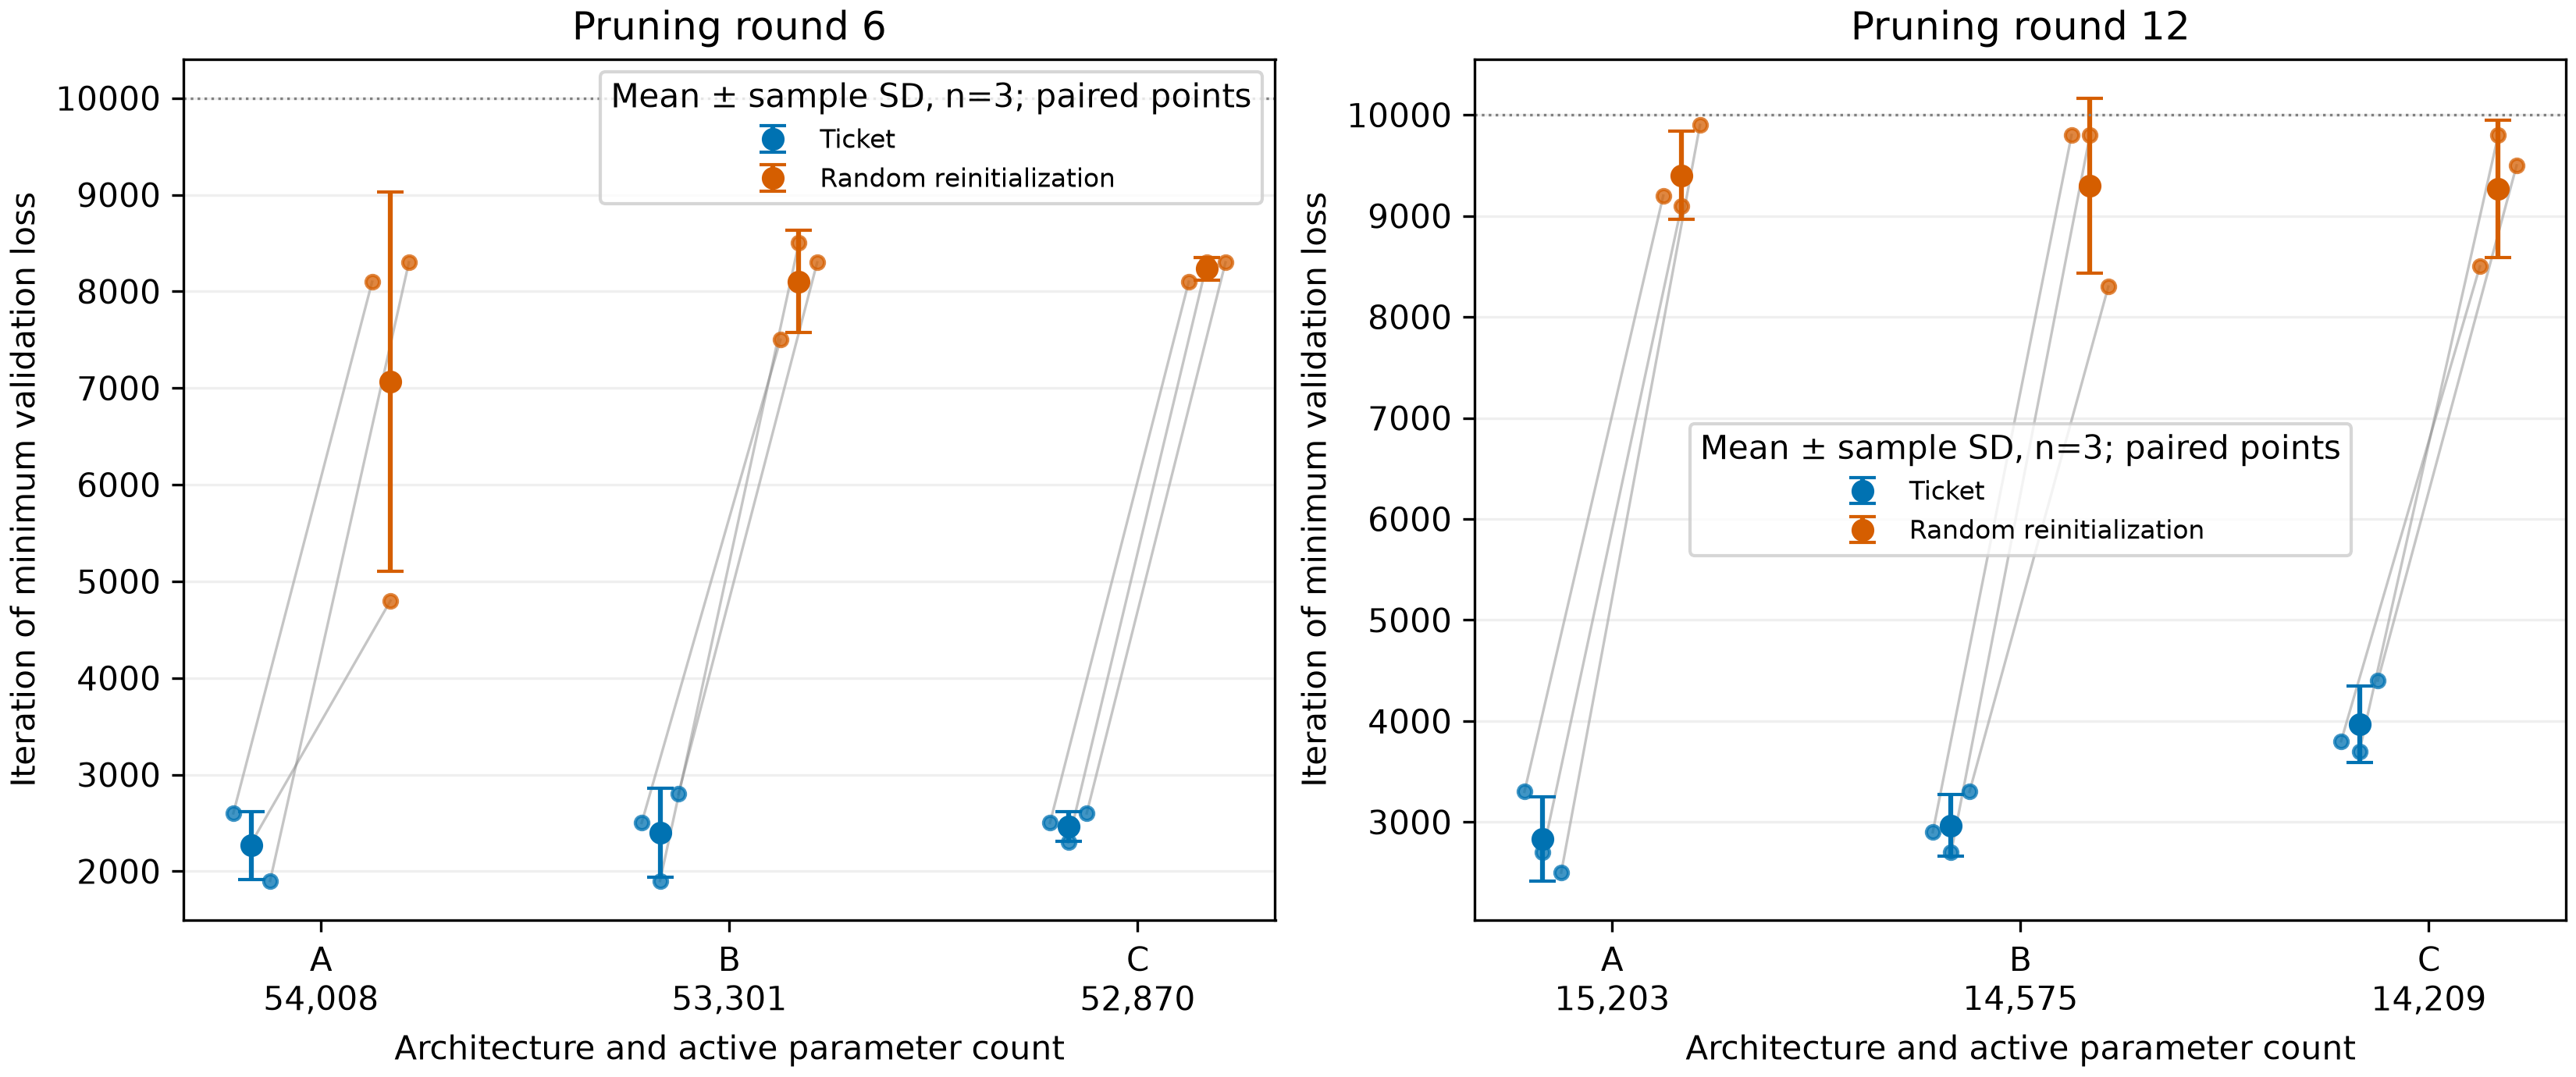

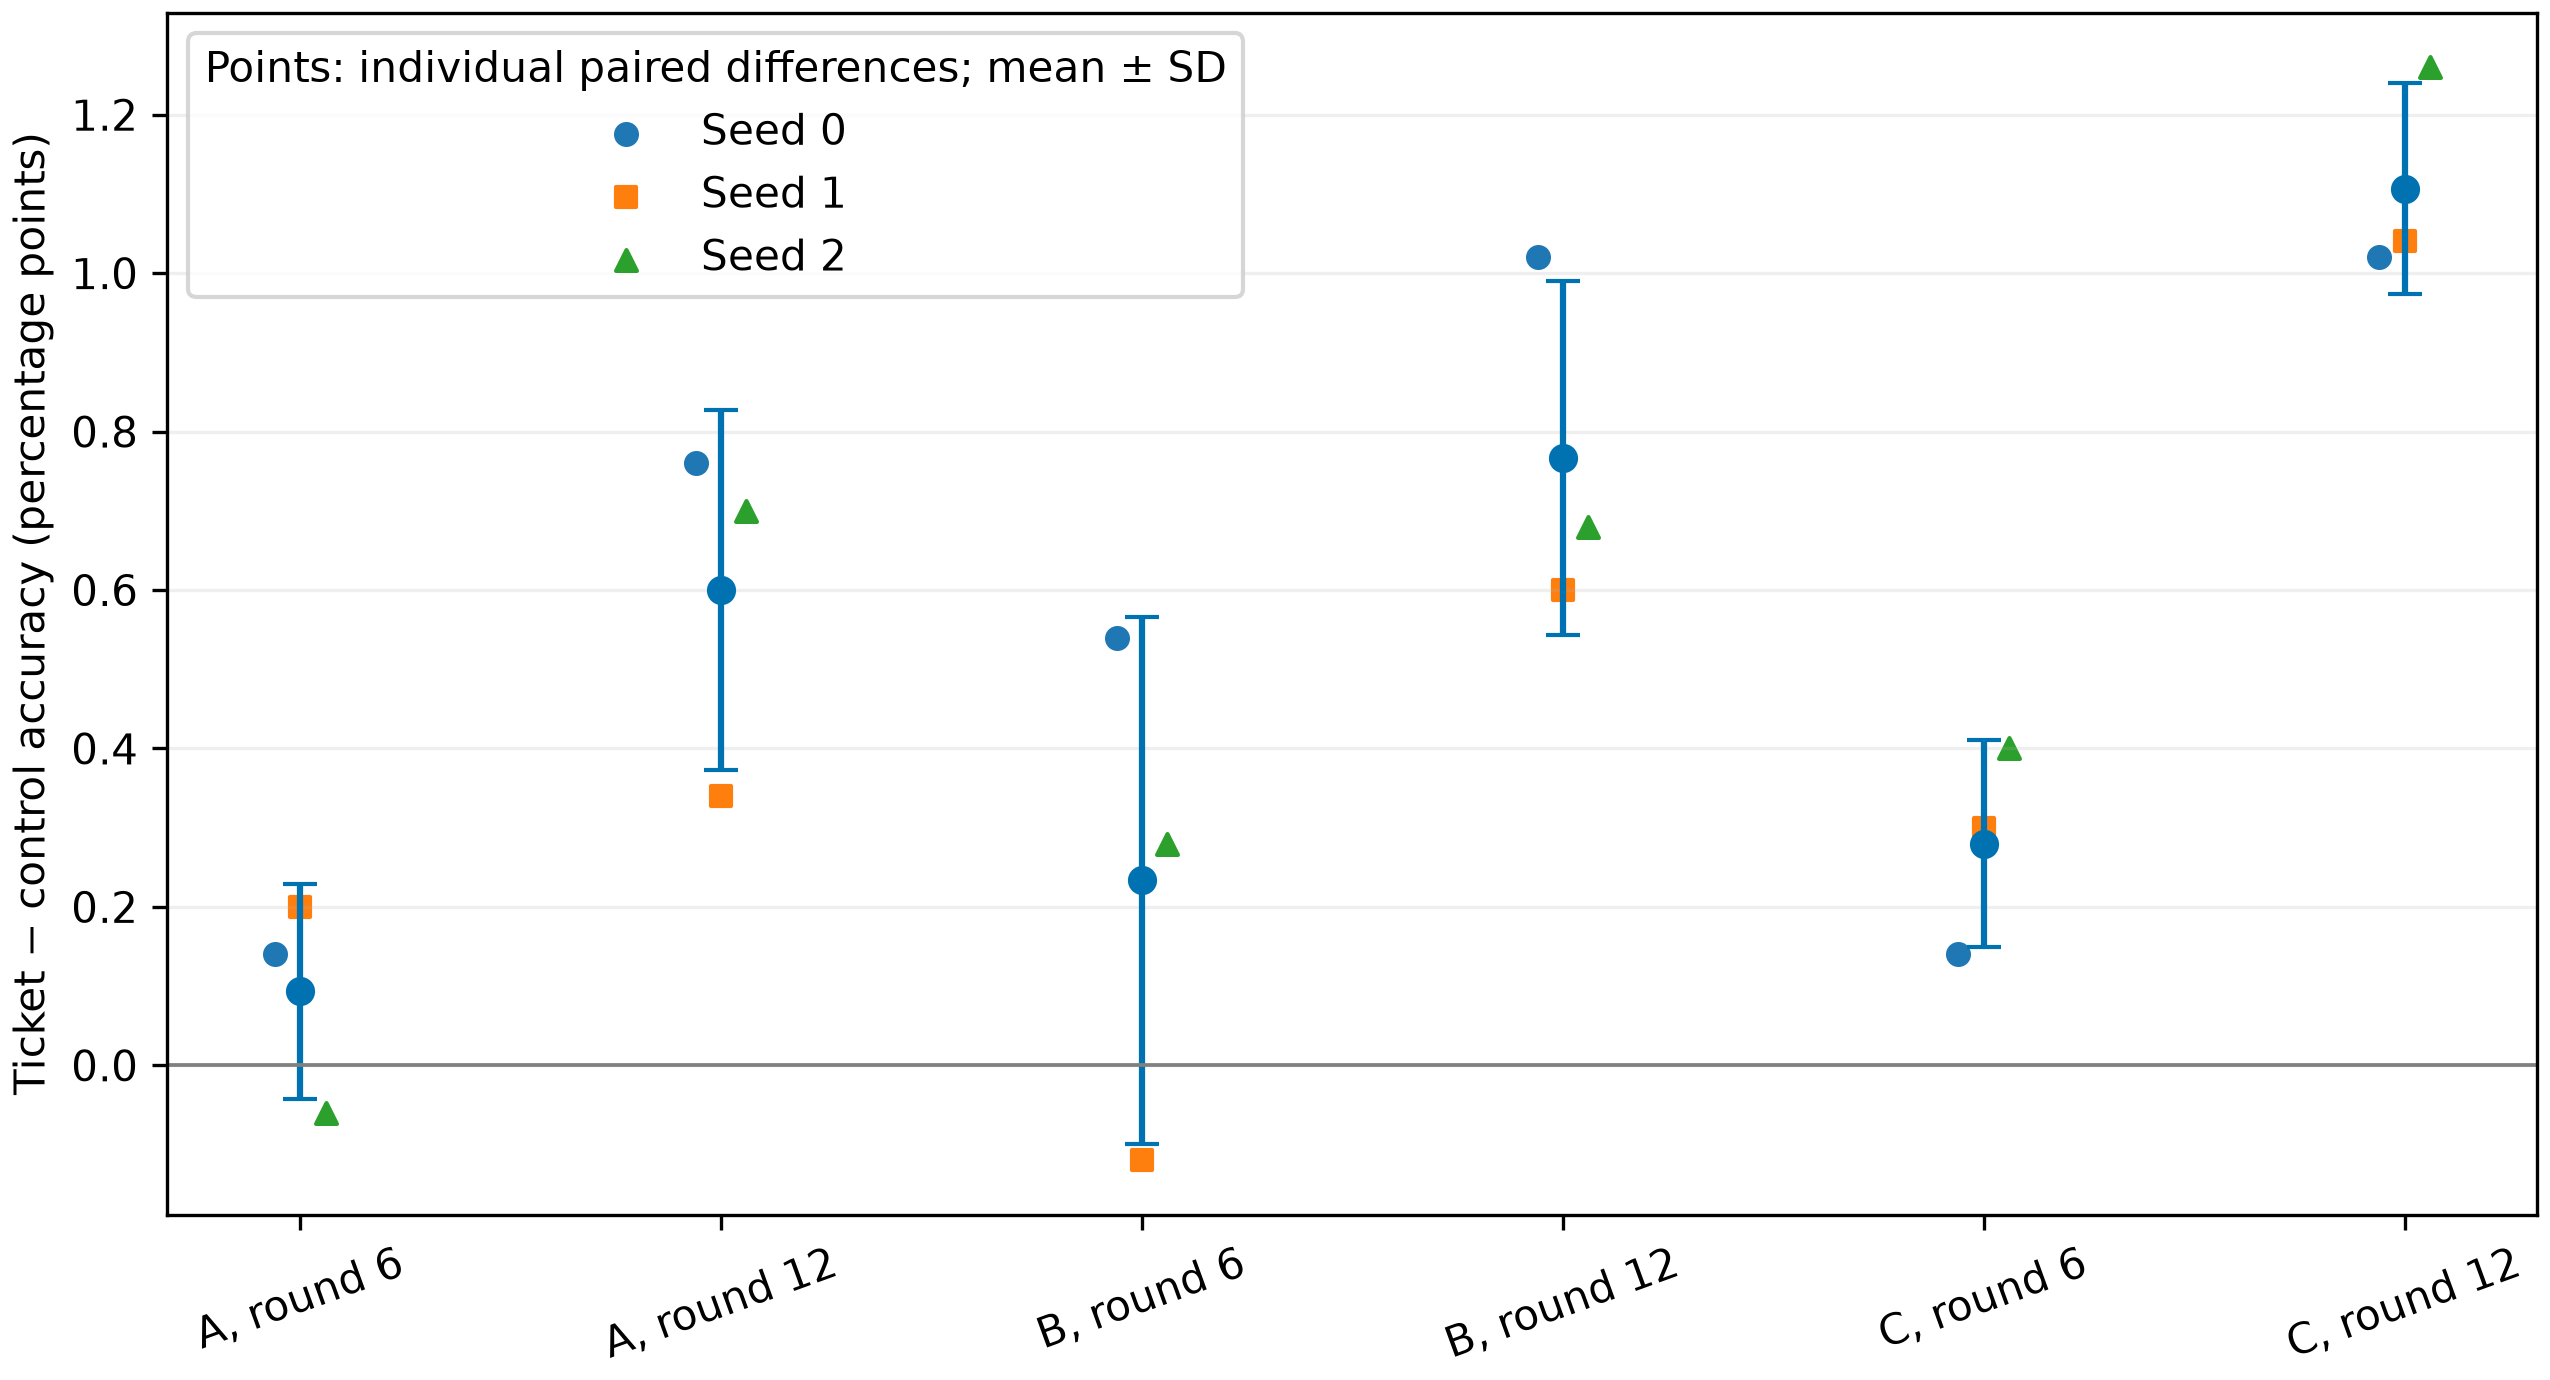

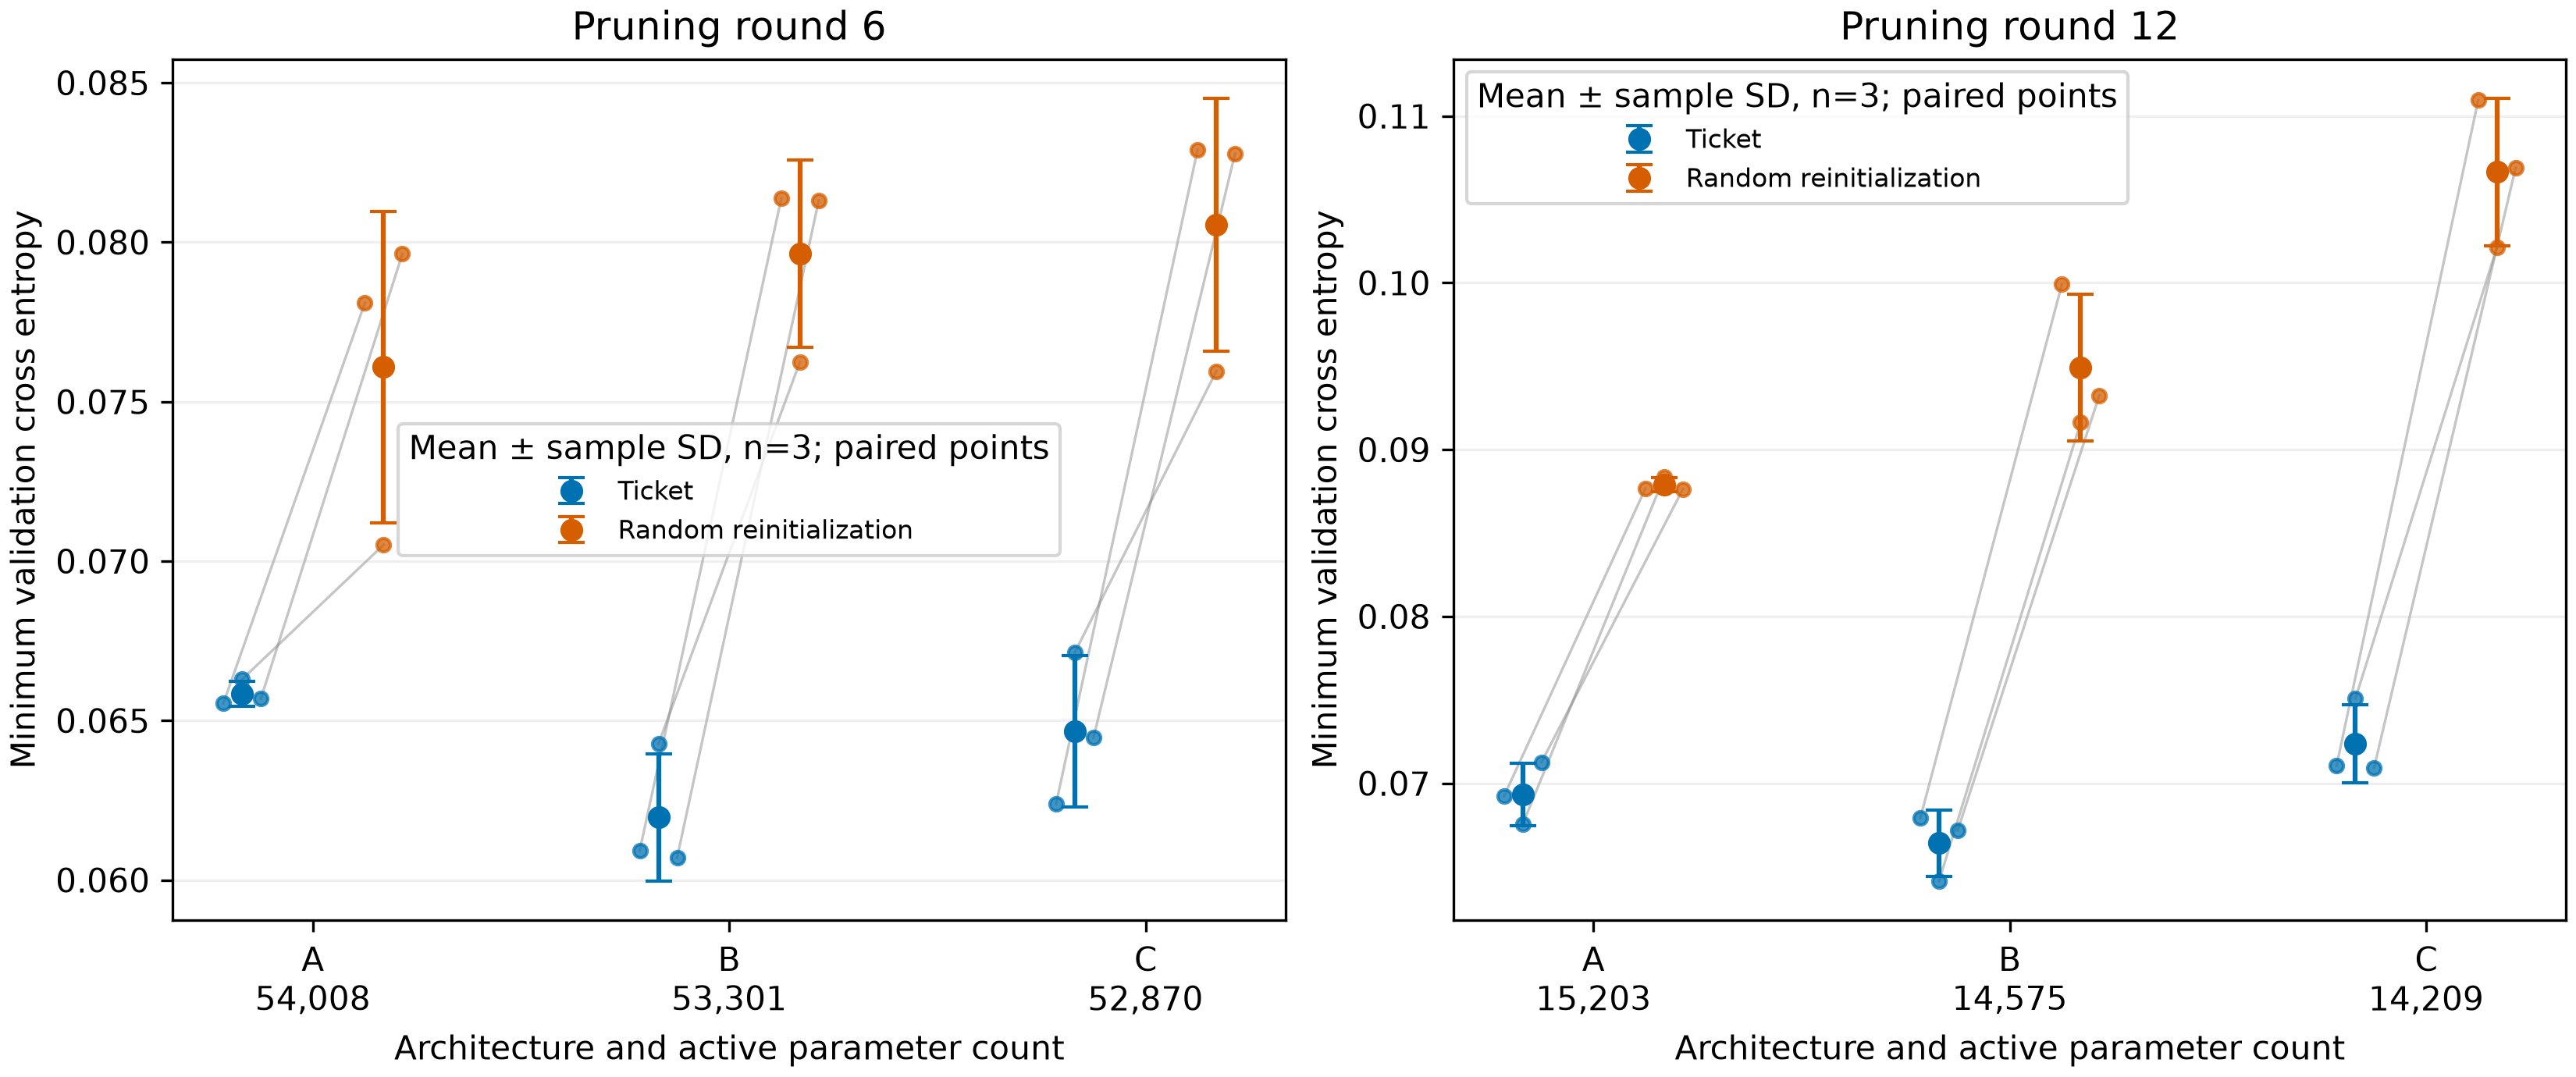

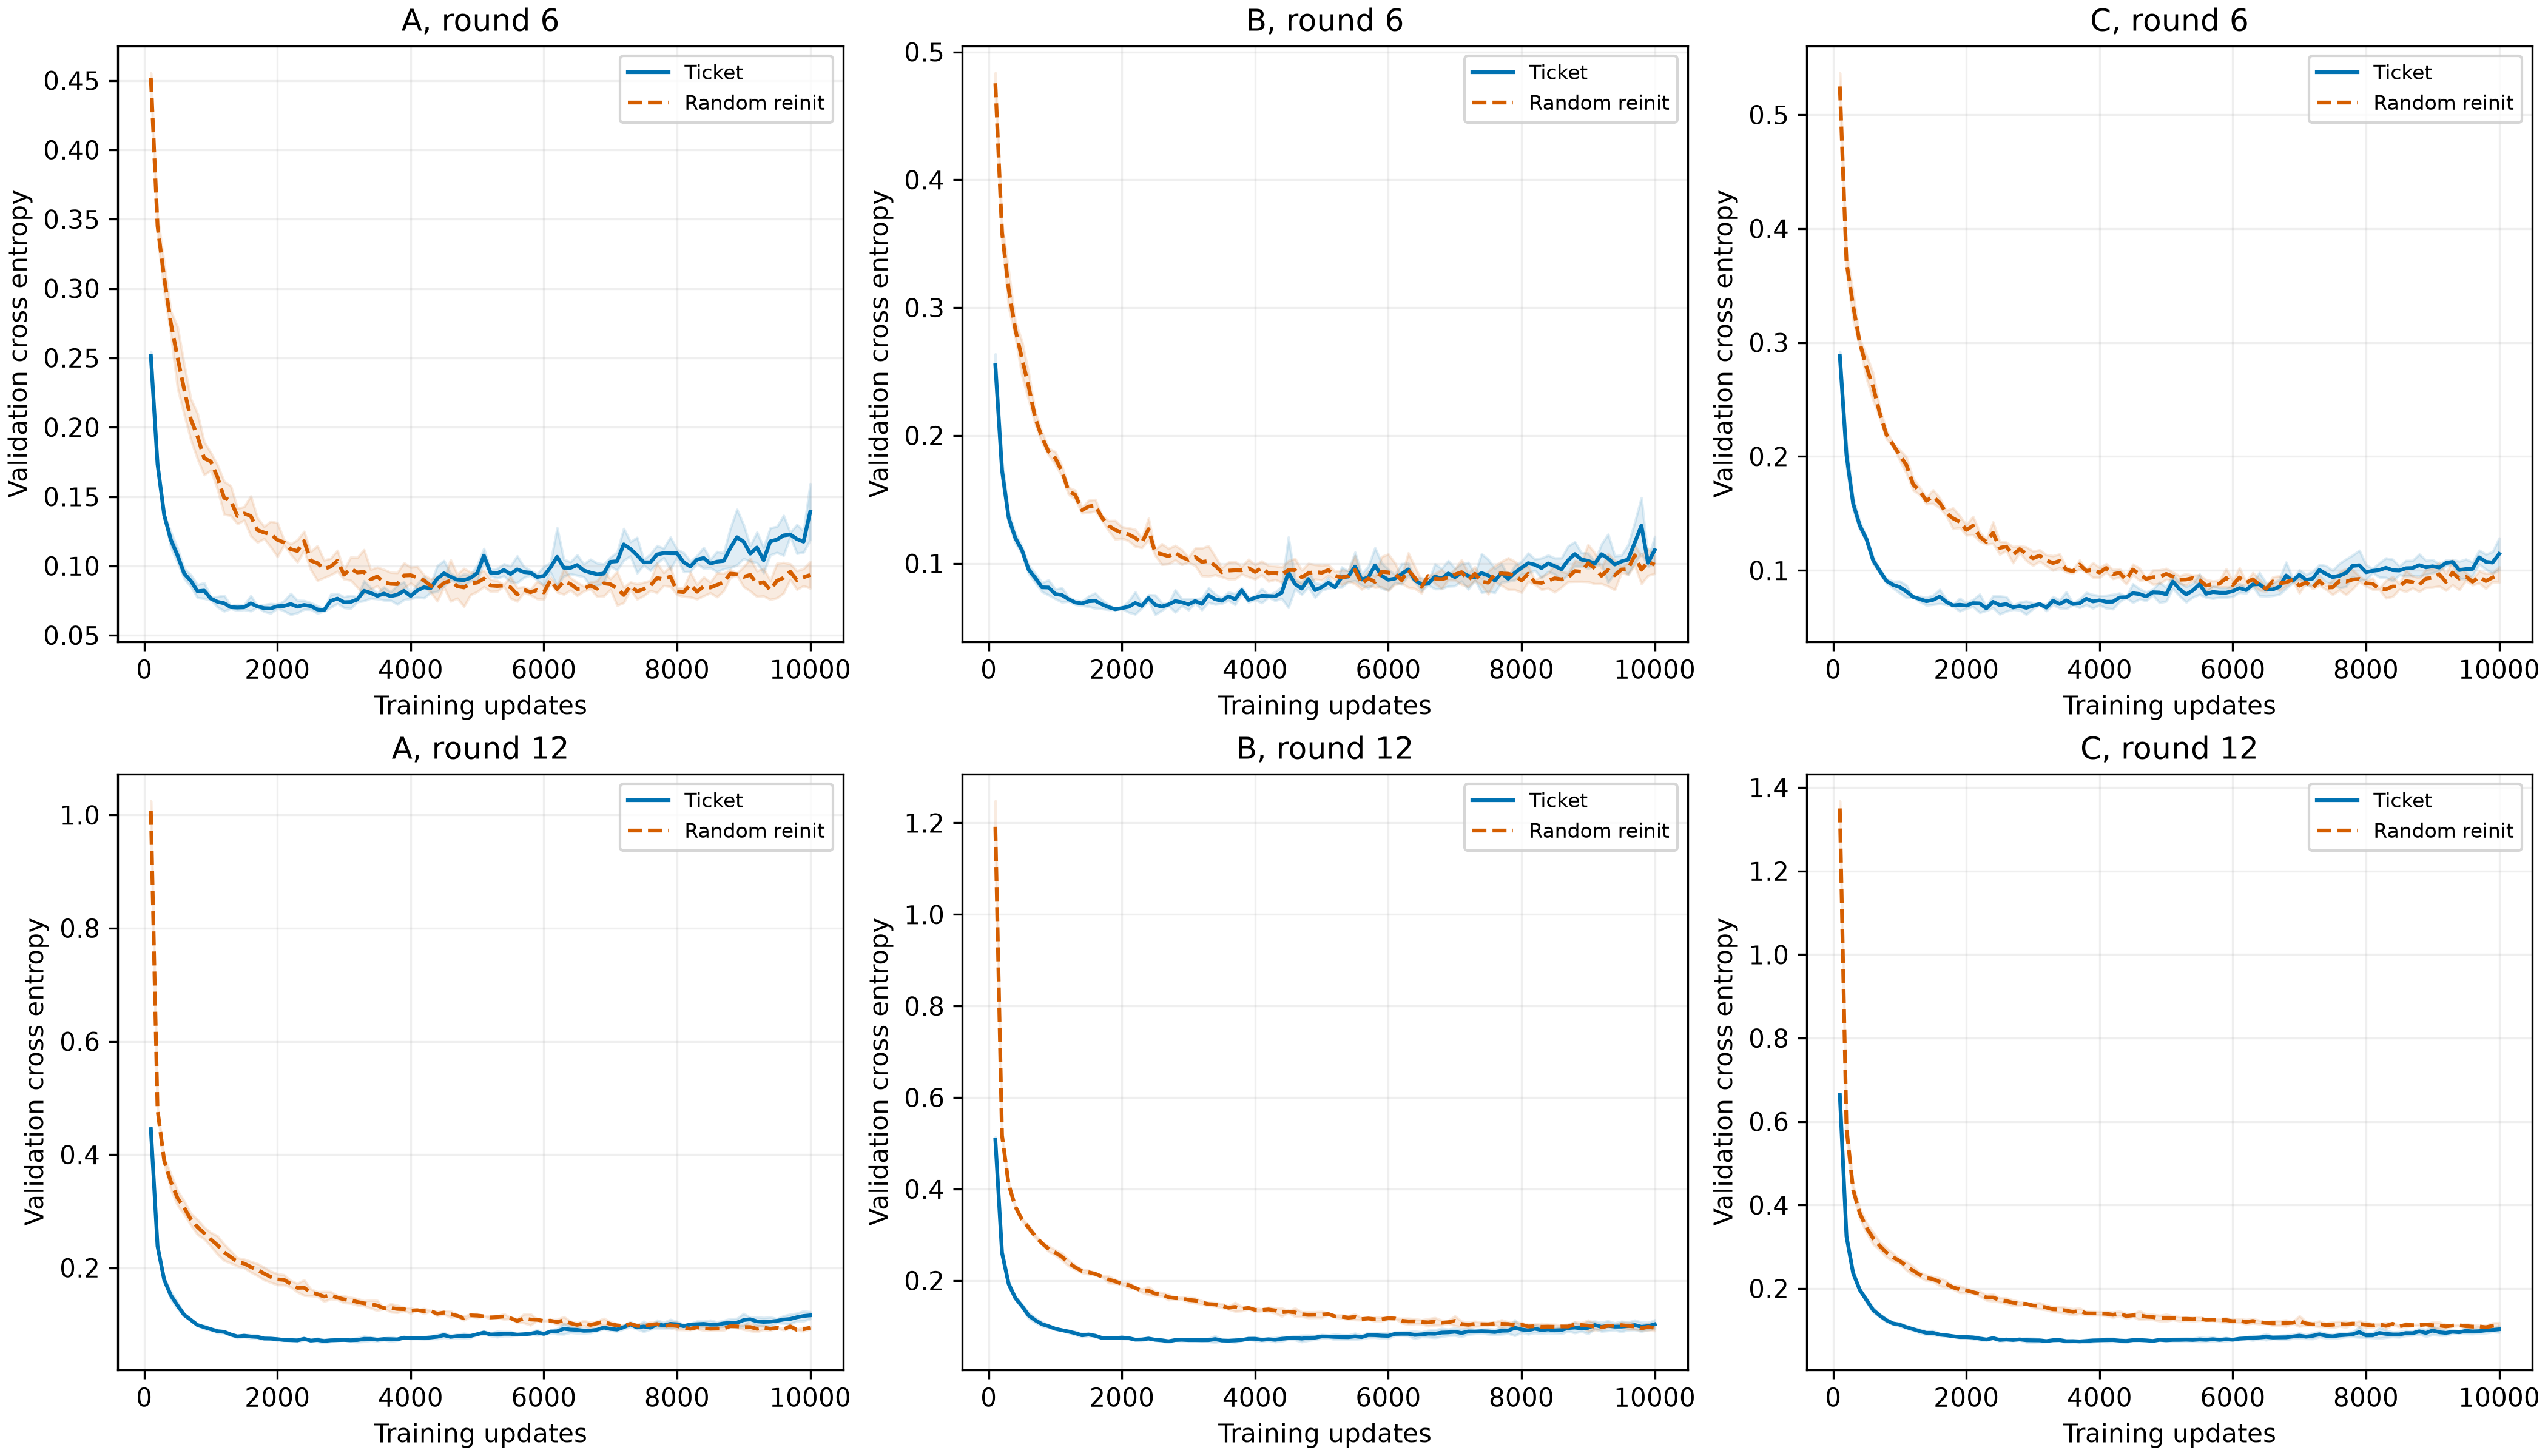

In [3]:
from stage4_controls_analysis import collect_results,save_figures,verify_controls,write_report
controls,pairs,summary,individual,aggregate,history=collect_results()
assert len(controls)==18 and len(pairs)==18 and len(history)==3600
assert history.selection_eligible.all()
display(pairs[["architecture","seed","stage","remaining_parameters_ticket",
    "best_validation_accuracy_ticket","best_validation_accuracy_control","ticket_minus_control_accuracy_pp",
    "best_validation_loss_ticket","best_validation_loss_control","best_iteration_ticket","best_iteration_control"]])
display(summary)
save_figures(pairs,summary,individual,aggregate,history)
for name in ("accuracy_ticket_vs_control","min_loss_iteration_ticket_vs_control",
             "paired_accuracy_differences","minimum_loss_ticket_vs_control","validation_loss_trajectories"):
    display(Image(filename=str(REPORT/"figures"/f"{name}.png")))

## Verify saved artifacts without ticket retraining or test evaluation

Recreate only the fresh untrained control initialization from its seed; check exact mask positions and initial/best/final zeros. Validate observed training-index hashes and final sampler state against the frozen ticket loader/split replay. The original ticket runs did not record fetch hashes, so this is reproducible reconstruction of their data-order protocol, not a fabricated historical audit.

Reload each saved control best snapshot and reproduce its **validation** metrics. This is a verification forward pass, not an extra training experiment. Hash every prior report/result/notebook unchanged. The checkpoint audit distinguishes available final ticket weights from missing selected-best ticket states.

In [4]:
verification=verify_controls()
display(verification)
tests=subprocess.run([sys.executable,"-m","pytest","-q"],capture_output=True,text=True)
(REPORT/"tests.txt").write_text(tests.stdout+tests.stderr)
print(tests.stdout)
tests.check_returncode()
report=write_report(controls,pairs,summary,aggregate)
display(Markdown(report))

{'status': 'verified',
 'controls': 18,
 'original_tickets_retrained': 0,
 'test_evaluated': False,
 'prior_files_unchanged': 1072,
 'checks': [{'architecture': 'A',
   'seed': 0,
   'stage': 6,
   'mask_matches_exactly': True,
   'fresh_initialization_reproduced': True,
   'batch_order_matches_ticket_protocol': True,
   'source_batch_order_basis': 'Reconstructed exact split/loader RNG protocol; original fetch hashes were not recorded',
   'masked_start_best_final_zero': True,
   'in_training_mask_checks': 100,
   'best_checkpoint_validation_reproduced': True,
   'original_ticket_retrained': False},
  {'architecture': 'A',
   'seed': 0,
   'stage': 12,
   'mask_matches_exactly': True,
   'fresh_initialization_reproduced': True,
   'batch_order_matches_ticket_protocol': True,
   'source_batch_order_basis': 'Reconstructed exact split/loader RNG protocol; original fetch hashes were not recorded',
   'masked_start_best_final_zero': True,
   'in_training_mask_checks': 100,
   'best_checkpoi

........................................................................ [ 80%]
..................                                                       [100%]
90 passed in 7.22s



# Stage 4A — same-mask random-reinitialization controls

**Exactly 18 approved controls completed**, across A/B/C × seeds 0/1/2 × pruning rounds 6/12. No original tickets were retrained, no masks regenerated, and the held-out test set was not evaluated. Final tests: **90 passed in 7.22s**.

## Does original initialization help?

Original-initialization tickets had higher selected validation accuracy in **16/18** pairs, lower accuracy in **2/18**, and tied in **0/18**. Original initialization was beneficial in many observed cases, but it did not uniformly outperform random reinitialization. Individual outcomes and each architecture/round's three-seed results matter.

Accuracy exceptions where random reinitialization was higher: **A/seed 2/round 6 (-0.060 pp), B/seed 1/round 6 (-0.120 pp)**.

| Model | Round | Active parameters | Ticket accuracy (%), mean ± SD | Control accuracy (%), mean ± SD | Ticket − control (pp), mean ± SD | Ticket wins/ties/losses |
|---|---:|---:|---:|---:|---:|---|
| A | 6 | 54,008 | 98.00 ± 0.11 | 97.91 ± 0.08 | +0.093 ± 0.136 | 2/0/1 |
| B | 6 | 53,301 | 98.10 ± 0.11 | 97.87 ± 0.22 | +0.233 ± 0.332 | 2/0/1 |
| C | 6 | 52,870 | 98.02 ± 0.12 | 97.74 ± 0.02 | +0.280 ± 0.131 | 3/0/0 |
| A | 12 | 15,203 | 97.93 ± 0.01 | 97.33 ± 0.23 | +0.600 ± 0.227 | 3/0/0 |
| B | 12 | 14,575 | 98.09 ± 0.05 | 97.33 ± 0.23 | +0.767 ± 0.223 | 3/0/0 |
| C | 12 | 14,209 | 97.89 ± 0.13 | 96.79 ± 0.08 | +1.107 ± 0.133 | 3/0/0 |

Differences are **ticket minus its corresponding control**, calculated within architecture, model seed and exact mask before aggregation. SD is the **sample SD of the three paired differences**, not a combination of independent SDs or a confidence interval. Accuracy is at each run's own minimum validation loss, sampled every 100 updates. The original metrics are reused from Stage 3's approved fine grid.

- Round 6: paired accuracy differences A +0.093 ± 0.136 pp, B +0.233 ± 0.332 pp, C +0.280 ± 0.131 pp; ticket wins 7/9, losses 2/9, ties 0/9.
- Round 12: paired accuracy differences A +0.600 ± 0.227 pp, B +0.767 ± 0.223 pp, C +1.107 ± 0.133 pp; ticket wins 9/9, losses 0/9, ties 0/9.

## Loss and trainability

| Model | Round | Ticket minimum loss, mean ± SD | Control minimum loss, mean ± SD | Ticket minimum iteration, mean ± SD | Control minimum iteration, mean ± SD |
|---|---:|---:|---:|---:|---:|
| A | 6 | 0.0658 ± 0.0004 | 0.0761 ± 0.0049 | 2267 ± 351 | 7067 ± 1966 |
| B | 6 | 0.0620 ± 0.0020 | 0.0796 ± 0.0029 | 2400 ± 458 | 8100 ± 529 |
| C | 6 | 0.0647 ± 0.0024 | 0.0805 ± 0.0040 | 2467 ± 153 | 8233 ± 115 |
| A | 12 | 0.0693 ± 0.0019 | 0.0879 ± 0.0004 | 2833 ± 416 | 9400 ± 436 |
| B | 12 | 0.0664 ± 0.0020 | 0.0949 ± 0.0044 | 2967 ± 306 | 9300 ± 866 |
| C | 12 | 0.0724 ± 0.0023 | 0.1067 ± 0.0044 | 3967 ± 379 | 9267 ± 681 |

Tickets reached their selected minimum earlier in **18/18** pairs and had lower minimum validation loss in **18/18**. These counts are descriptive, not 18 independent hypothesis-test replicates. The two pruning rounds share parent experiments, seeds and a fixed validation dataset.

Control minima in updates 8,000–10,000: **16/18**; exactly at update 10,000: **0/18**. Late control minima can indicate budget-limited learning. Consequently, accuracy gaps establish behavior at the specified **10,000-update budget**, not an asymptotic inability of randomly initialized networks to catch up. The budget was not changed for any architecture or outcome. The original paper's 50,000-update setting remains a documented deviation.

## What this adds to the width-ratio research question

The initialization benefit increased from round 6 to round 12 in **9/9** architecture–seed trajectories. At round 12, **C** showed the largest observed mean paired accuracy advantage, **+1.107 ± 0.133 pp**. This identifies stronger initialization sensitivity for those saved masks, not the best absolute ticket architecture. In Stage 3, B had the strongest dense-relative preservation; here the size of the initialization advantage is a separate quantity. In particular, C can depend more on its original initialization while still having lower absolute ticket accuracy than B. The ratios therefore appear to differ in initialization sensitivity under the specified sparsity/budget, but active counts/mask geometry differ and only three seeds were tested. No universally optimal ratio or statistically established cross-architecture superiority follows.

The control isolates initialization **within each saved mask**: architecture, active positions, data split, exact batch order, optimizer settings and budget are matched. It separates the behavior of the original-initialization IMP ticket from what a fresh initialization can do with the same selected connectivity. The paired tables show how initialization sensitivity differs among the tested width allocations; they must not be read as evidence that one ratio is universally best.

Stage 3's dense-relative preservation and Stage 4's initialization advantage answer different questions. A ratio may preserve its dense accuracy well yet have a small initialization advantage, or show a large ticket/control gap because its random control learns slowly. Compare absolute ticket accuracy, paired gaps, minimum-loss iteration and individual seeds together. At round 12, active counts are A 15,203, B 14,575, C 14,209; identical rounds are **not exactly parameter-matched across architectures**. Thus cross-architecture differences in control benefit combine allocation and the resulting mask/sparsity geometry. Within each pair the positions and count are exactly identical.

Only three model seeds and one predetermined fresh initialization per mask were used. Mean ± SD and individual paired observations describe these runs; there are no population-level significance claims or post-hoc seed searches. The fixed validation split, many correlated comparisons, finite budget and unevaluated test set limit stronger generalization. This is evidence about initialization under this protocol, not a claim that every ticket beats every random initialization or that any ratio is statistically superior.

## Verification and preservation

- Exact source masks were copied, not regenerated. Start, selected-best and final control states match all saved active positions and keep masked weights zero; masks were also checked at all 100 training validation events.
- Full fresh Gaussian Glorot states were reproduced bit for bit from the predetermined seed rule `(model_seed + 1000003 + round*1009) % 2**32`, with zero biases, and differ from the corresponding original initialization on surviving weights.
- Each control's **observed** training fetch stream and final sampler RNG state match replay of the source ticket's exact split/loader protocol for all 10,000 updates, including partial batches and epoch reshuffles. Original Stage 3 fetch hashes were not recorded, so this is verified reconstruction from the frozen code, versions, split and seeds; no ticket training was replayed.
- A fresh Adam is created for each run. All original source checkpoints/masks and **1072 prior files** remained unchanged by checksum comparison.
- Actual saved control `best_validation.pt` states reproduce the selected validation loss/accuracy when reloaded. This verification used validation only, never the held-out test loader.

See `verification.json`, `protocol.lock.json`, `batch_order_reference.json` and each run's committed artifacts. All tables/figures and full histories are under `reports/stage4_controls/`.

## Can final test evaluation proceed without retraining?

**Not at Stage 3's reported minimum-loss ticket states.** The audit inspected all 117 source stages: only original/start/final 10,000-update tensors were saved, and no selected minimum occurred at update 10,000. Thus **0/117 selected ticket states are currently available** without replay. Histories and metrics cannot substitute for weights.

Saved starts/masks/seeds allow a separately authorized deterministic training replay to each selected iteration, followed by validation-metric reproduction. That would be ticket retraining/replay and is **not performed here**. Do not regenerate masks or silently replace the reported states.

The saved final 10,000-update ticket checkpoints can be evaluated without retraining **if a distinct final-weight test estimand is explicitly chosen**. It would not be the validation-selected evaluation currently reported. Controls now have actual minimum-loss snapshots, so their selected test evaluation would not require control retraining; paired selected-state ticket testing still needs the missing ticket states. See `stage3_checkpoint_audit.csv/md` for the complete audit.

## Runtime and scope

Actual orchestration wall time: **6.44 minutes**, with three isolated one-thread CPU worker processes. Summed control training/validation wall times: **17.85 minutes**, overlapping under parallel execution and including audit/checkpoint callback overhead. No GPU timings are claimed. Only these 18 control trainings were executed; unit/integration tests use synthetic data and are not extra MNIST experiments. No additional diagnostics, ticket replays or test-set evaluations were launched.


Stop here before held-out testing. Stage 3 lacks minimum-loss ticket weights: selected-state testing needs separately authorized deterministic replay from saved starts/masks/seeds to each selected iteration. Testing the existing final-10k states is possible without training, but is a different estimand and must not silently replace the selected-state results. New control best snapshots are available. No additional experiment, ticket replay or test evaluation is launched automatically.